In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import os
import sys
import pyabc
import seaborn as sns

import healpy as hp
from scipy.special import sph_harm
from scipy.stats import norm
import skyproj
from astropy.coordinates import SkyCoord, Angle
import astropy.units as u

sys.path.insert(0, '/work2/08811/aew492/frontera/lss-dipoles/code')
import tools
import dipole
import multipoles
import generate_mocks as gm
from abc_for_qso import get_catalog_info
from abc_fake_data import generate_fake_data

In [2]:
def get_abc_results_free_dipole(fn, verbose=True):

    res = np.load(fn, allow_pickle=True).item()
    history = res['history']
    prior = res['prior']
    posterior = res['posterior']
    selfunc = res['selfunc']
    expected_dipamp = res['expected_dipole_amp']
    if verbose:
        print(f"expected dipole_amp = {expected_dipamp}")

    # quantiles
    df, w = posterior
    par_ids = [x for x in prior.keys()]
    q = np.array([
        tools.quantile(df[par_id], [0.16, 0.5, 0.84], weights=w) for par_id in par_ids
    ])
    # get the inferred dipole from the median posterior
    
    # if the parameters are (x,y,z):
    if 'dipole_x' in par_ids:
        # then the median posterior are the inferred dipole (x,y,z) components
        inferred_dipole_comps = q[:,1]
        dipamps = np.linalg.norm(df, axis=1)
        expected_values = tools.dipole_dir_to_comps(dipole.cmb_dipole()[1]) * expected_dipamp
    # else if the parameters are (rho, costheta, phi)
    elif 'rho' in par_ids:
        inferred_dipole_comps = tools.rho_costheta_phi_to_xyz(*q[:,1])
        dipamps = df['rho']
        expected_dir = dipole.cmb_dipole()[1].icrs
        # get (theta, phi) in (RA, Dec)!
        theta, phi = tools.lonlat_to_thetaphi(expected_dir.ra, expected_dir.dec)
        expected_values = np.array([expected_dipamp, np.cos(theta.rad), phi.rad])
    else:
        raise ValueError("unrecognized par_ids")
    dipamp, dipdir = dipole.get_dipole(inferred_dipole_comps)
    
    if verbose:
        print("inferred dipole comps: ", inferred_dipole_comps)
        print(f"inferred dipole has amplitude {dipamp:.5f} towards (l, b) = ({dipdir.galactic.l.deg:.2f}, " + \
              f"{dipdir.galactic.b.deg:.2f}) deg")

    # Z score
    q_amp = tools.weighted_quantile(dipamps, w, [0.16, 0.5, 0.84])
    sigma = pyabc.weighted_statistics.weighted_std(dipamps, w)
    z = (q_amp[1] - expected_dipamp) / sigma
    if verbose:
        print(f"Z score = {z:.4f}")

    return q, res, dipamp, dipdir, expected_values, z

In [3]:
def standard_dipole(qmap_masked, selfunc, expected_dipole_amp=None):

    # mask
    qmap_masked[np.isnan(qmap_masked)] = 0.  # need to turn NaNs into zeros in order to downgrade the resolution properly
    # correct by selfunc
    qmap_corr = qmap_masked / selfunc
    # overdensity map
    odmap = qmap_corr / np.nanmean(qmap_corr) - 1
    # inverse variance
    odmap_Cinv = selfunc * np.nanmean(qmap_corr)

    # measure dipole
    dipcomps, stderr = dipole.measure_overdensity_dipole_Lambda(odmap, 0., Cinv=odmap_Cinv, return_err=True)
    dipamp, dipdir = dipole.get_dipole(dipcomps)
    
    # propagate error
    dipamp_std, theta_std, phi_std = tools.dipamp_err(dipcomps, stderr)
    
    res = {
        'dipamp' : dipamp,
        'dipamp_std' : dipamp_std,
        'dipdir' : dipdir,
        'dipdir_std' : theta_std
    }
    
    if expected_dipole_amp is not None:
        res['relamp'] = dipamp / expected_dipole_amp
        res['relstd'] = dipamp_std / expected_dipole_amp
        res['zscore'] = (expected_dipole_amp - dipamp) / dipamp_std
    
    return res

In [4]:
blim = 30
nside = 2
nside_hi = 64
resdir = '/work2/08811/aew492/frontera/lss-dipoles/results'

# expected dipole direction
cmb_dipdir = dipole.cmb_dipole()[1]

### load fake data: ideal Quaia G20.0: kinematic dipole + shot noise (no excess power)

In [5]:
# ideal Quaia G20.0: kinematic dipole + shot noise (no excess power)
sample_name = 'quaia_G20.0'
cat_info = get_catalog_info(sample_name)
base_rate = cat_info['base_rate']
selfunc_str = cat_info['selfunc_str']

# expected values
input_theta, input_phi = tools.lonlat_to_thetaphi(cmb_dipdir.ra, cmb_dipdir.dec)
input_dipole_amp = cat_info['expected_dipole_amp']
expected_values = [input_dipole_amp, np.cos(input_theta.rad), input_phi.rad]

ntrials = 100
nside = 2
nmocks = 500
niters = 15

In [11]:
# methods and colors
methods = ['MLE', 'ABC']
c_mle = 'mediumseagreen'
c_abc = 'royalblue'
cs = dict(MLE=c_mle, ABC=c_abc)

In [12]:
abc_dict = {
    'quantiles' : {},
    'dipdirs' : {},
    'dipamp_stds' : {},
    'dipdir_stds' : {},
    'posteriors' : {}
}
mle_dict = {
    'dipamps' : {},
    'dipdirs' : {},
    'dipamp_stds' : {},
    'theta_stds' : {},
    'phi_stds' : {}
}
fake_data_dipole_res = {
    'data' : {},
    'ABC' : abc_dict,
    'MLE' : mle_dict
}

In [13]:
for itrial in range(ntrials):
    # load the ABC results, including the fake data
    q, res, dipamp, dipdir, expected_vals, z = get_abc_results_free_dipole(os.path.join(resdir, 'ABC/fake_data',
                        f'{selfunc_str}_base-rate-{base_rate:.4f}_dipamp-1.0x_excess-zero/trials',
                        f'trial{itrial}',
                        f'free_dipole_nside{nside}_{nmocks}mocks_{niters}iters_flat-prior-spherical',
                                f'results.npy'), verbose=False)
    ### ABC results ###
    # get the weighed quantiles of the relative amplitude
    df, w = res['posterior']
    dipamps = df['rho']
    q_amp = tools.weighted_quantile(dipamps, w, [0.16, 0.5, 0.84])
    # and the standard deviation?
    mean = np.average(dipamps, weights=w)
    var = np.average((dipamps - mean)**2, weights=w)
    dipamp_std = np.sqrt(var)
    
    # and calculate the uncertainty in direction
    dipdir_std = tools.dipdir_b_err(df, w)
    # add results to the dict
    for (key, value) in zip(abc_dict.keys(),
                            [q_amp, dipdir, dipamp_std, dipdir_std, res['posterior']]):
        fake_data_dipole_res['ABC'][key][itrial] = value
    
    ### MLE results ###
    # get the selfunc-corrected data map
    datadict = res['fake_data_dict']
    selfunc = datadict['selfunc']
    input_dipamp = datadict['input_dipole_amp']

    # overdensity map
    datamap = datadict['data']['data'].astype(float)
    datamap[datamap == 0.] = np.nan
    fake_data_dipole_res['data'][itrial] = datamap
    datamap_corr = datamap / selfunc
    odmap = datamap_corr / np.nanmean(datamap_corr) - 1
    odmap_Cinv = selfunc * np.nanmean(datamap_corr) # inverse variance

    # measure dipole
    dipcomps, stderr = dipole.measure_overdensity_dipole_Lambda(odmap, 0., Cinv=odmap_Cinv, return_err=True)
    dipamp_lstsq, dipdir_lstsq = dipole.get_dipole(dipcomps)

    # propagate error
    dipamp_std, theta_std, phi_std = tools.dipamp_err(dipcomps, stderr)
    # add results to the dict
    for (key, value) in zip(mle_dict.keys(),
                            [dipamp_lstsq, dipdir_lstsq, dipamp_std, theta_std, phi_std]):
        fake_data_dipole_res['MLE'][key][itrial] = value

In [14]:
# unpack the dipole amplitudes
dipamp_abc_grid = np.array([
    fake_data_dipole_res['ABC']['quantiles'][itrial][1] for itrial in range(ntrials)
]) # medians
dipamp_mle_grid = np.array(list(fake_data_dipole_res['MLE']['dipamps'].values())) # means (?)
dipamp_grids = {
    'MLE' : dipamp_mle_grid,
    'ABC' : dipamp_abc_grid
}

In [15]:
# medians and standard deviations?
dipamp_medians = {}
dipamp_stds = {}
for method, grid in dipamp_grids.items():
    dipamp_medians[method] = np.median(grid)
    dipamp_stds[method] = np.std(grid)
    print(f"dipole amp from {method} = {dipamp_medians[method]:.5f} ± {dipamp_stds[method]:.5f}")

dipole amp from MLE = 0.00619 ± 0.00249
dipole amp from ABC = 0.00511 ± 0.00221


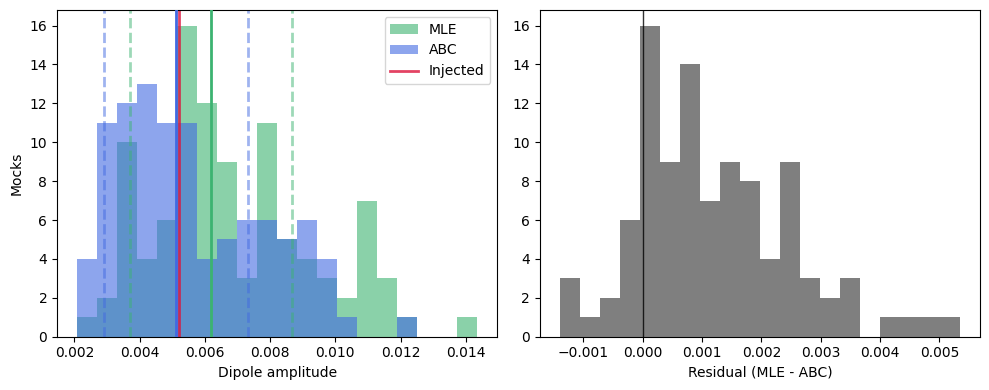

In [11]:
# histogram
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10,4), tight_layout=True)
nbins = 20
bins = np.linspace(np.amin(list(dipamp_grids.values())),
                   np.amax(list(dipamp_grids.values())), nbins+1)
# medians and standard deviations
for method in methods:
    c = cs[method]
    med = dipamp_medians[method]
    std = dipamp_stds[method]
    _, _, _ = ax0.hist(dipamp_grids[method], color=c, alpha=0.6, bins=bins,
                       histtype='stepfilled', label=method, lw=2)
    ax0.axvline(med, c=c, alpha=1, lw=2, zorder=100)
    for x in (med - std, med + std):
        ax0.axvline(x, color=c, alpha=0.5, ls='--', lw=2)
    
_, _, _ = ax1.hist(dipamp_grids['MLE'] - dipamp_grids['ABC'], color='k', alpha=0.5,
                      histtype='stepfilled', lw=2, bins=nbins)
ax0.axvline(input_dipole_amp, c='crimson', lw=2, alpha=0.8, label='Injected')
ax1.axvline(0, c='k', lw=1, alpha=0.8)
ax0.set_xlabel('Dipole amplitude')
ax1.set_xlabel('Residual (MLE - ABC)')
ax0.set_ylabel('Mocks')
ax0.legend()

Text(0.5, 0.98, 'ABC with 100 Quaia G20.0-like mocks')

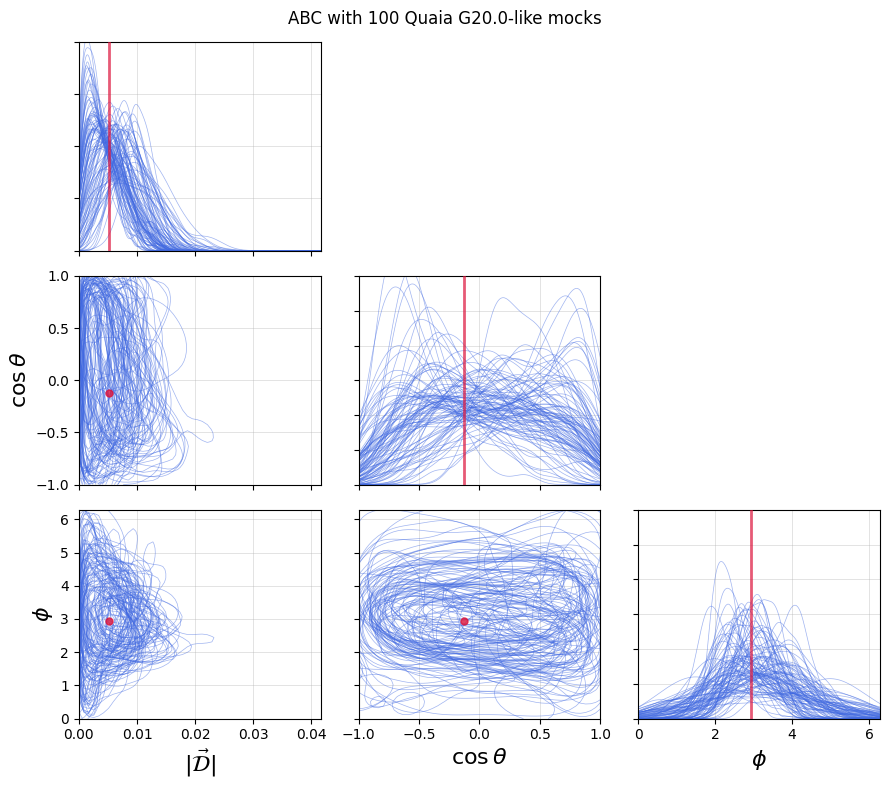

In [12]:
# overplot all the posteriors
# plot the posterior for each trial:
posteriors = fake_data_dipole_res['ABC']['posteriors'].values()
# prior and parameter IDs:
prior = res['prior']
par_ids = list(prior.keys())

fig, axs = plt.subplots(len(par_ids), len(par_ids), figsize=(9,8), tight_layout=True)
        
# color things etc
c = c_abc
ylims = [200, 1.5, 1.5]
# alphas for the contour plot
alphas = [0.5]
par_labels = [r'$|\vec{\mathcal{D}}|$', r'$\cos\theta$', r'$\phi$']

for i, (par_id, par_label, ylim) in enumerate(zip(par_ids, par_labels, ylims)):
    
    # diagonal
    ax = axs[i, i]
    label = 'Expected' if i == 0 else ''
    ax.axvline(expected_values[i], c='crimson', alpha=0.7, lw=2, label=label, zorder=30)

    for posterior in posteriors:
        x, pdf = tools.get_kde_1d(list(posterior), prior, par_id, numx=500)
        ax.plot(x, pdf, c=c, alpha=0.5, lw=0.5, ls='-')
    ax.set_ylim(0., ylim)
    ax.set_xlim(prior[par_id].args[0], prior[par_id].args[0] + prior[par_id].args[1])
    ax.grid(alpha=0.5, lw=0.5)
    if i != 2:
        ax.set_xticklabels([])
    ax.set_yticklabels([])

    if i != 0:
        axs[i,0].set_ylabel(par_label, fontsize=16)
    axs[len(par_ids)-1,i].set_xlabel(par_label, fontsize=16)

    for j in range(0, i):

        # lower
        ax = axs[i, j]
        for posterior in posteriors:
            x, y, pdf = tools.get_kde_2d(list(posterior), prior, par_ids[j], par_id)
            levels = tools.convert_posterior_levels(pdf, plevels=[0.68])
            for lvl, a in zip(levels, alphas):
                ax.contour(x, y, pdf, levels=[lvl], colors=c, linewidths=0.5, alpha=a, linestyles='-')
        ax.plot(expected_values[j], expected_values[i], c='crimson', marker='.', alpha=0.8, ms=10, zorder=30)
        ax.grid(alpha=0.5, lw=0.5)
        ax.set_xlim(prior[par_ids[j]].args[0], prior[par_ids[j]].args[0] + prior[par_ids[j]].args[1])
        ax.set_ylim(prior[par_id].args[0], prior[par_id].args[0] + prior[par_id].args[1])
        if i == 2 and j == 1:
            ax.set_yticklabels([])
        if i == 1:
            ax.set_xticklabels([])

        # upper
        axs[j,i].set_axis_off()
fig.suptitle(f'ABC with {ntrials} Quaia G20.0-like mocks')

In [13]:
# for how many of the mocks does the injected dipole amplitude fall within the 68% ETI?
n_within_eti = 0
for q in fake_data_dipole_res['ABC']['quantiles'].values():
    if input_dipole_amp > q[0] and input_dipole_amp < q[2]:
        n_within_eti += 1
print(f"{n_within_eti} of {ntrials} trials ({n_within_eti / ntrials * 100:.1f}%) have input dipole amp within 68% ETI")

87 of 100 trials (87.0%) have input dipole amp within 68% ETI


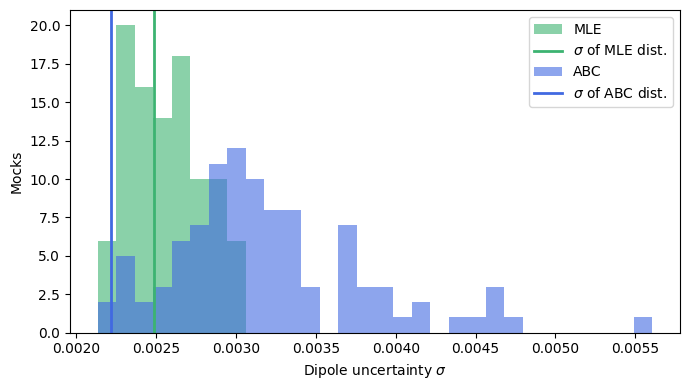

In [15]:
# how does the standard deviation from the trials compare to the uncertainties from the ABC posteriors?
fig, ax = plt.subplots(figsize=(7,4), tight_layout=True)
dipamp_stds_mocks = {}
for method in methods:
    dipamp_stds_mocks[method] = list(fake_data_dipole_res[method]['dipamp_stds'].values())
bins = np.linspace(np.amin(list([dipamp_stds_mocks[x] for x in methods])),
                   np.amax(list([dipamp_stds_mocks[x] for x in methods])), 31)
for method in methods:
    _, _, _ = ax.hist(dipamp_stds_mocks[method], color=cs[method], bins=bins,
                     alpha=0.6, label=method)
    ax.axvline(dipamp_stds[method], c=cs[method], lw=2, label=r'$\sigma$ of 'f'{method} dist.')
ax.set_xlabel(r'Dipole uncertainty $\sigma$')
ax.set_ylabel('Mocks')
ax.legend()

In [16]:
# directions
dipdirs_abc = np.array(list(fake_data_dipole_res['ABC']['dipdirs'].values()))
dipdirs_mle = np.array(list(fake_data_dipole_res['MLE']['dipdirs'].values()))

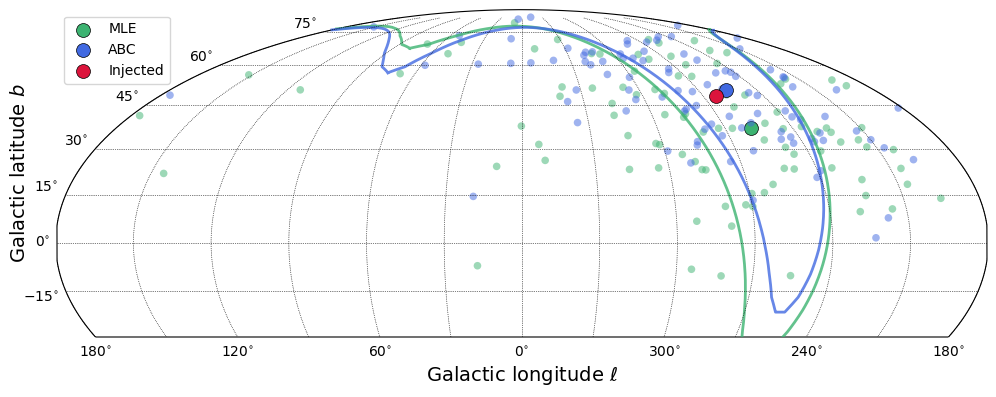

In [17]:
# direction
fig, ax = plt.subplots(figsize=(12,6))
sp = skyproj.MollweideSkyproj(ax=ax, extent=[0, 360, -30, 90])
sp.ax.tick_params(fontsize=16)

# labels and gridlines
sp.ax.set_xlabel(r'Galactic longitude $\ell$', fontsize=14)
sp.ax.set_ylabel(r'Galactic latitude $b$', fontsize=14)
sp.ax.tick_params(fontsize=12)
sp.ax.gridlines.set_alpha(0.4)

for method in methods:
    dipdirs = np.array(list(fake_data_dipole_res[method]['dipdirs'].values()))
    l, b = np.array([[dipdir.galactic.l.deg, dipdir.galactic.b.deg] for dipdir in dipdirs]).T
    sp.ax.scatter(l, b, color=cs[method], edgecolor='None', s=30, alpha=0.5, marker='o')
    
    sp.ax.scatter(np.median(l), np.median(b), marker='o', c=cs[method], s=100,
                 alpha=1., label=method, ec='k', lw=0.5)
    sp.ax.ellipse(np.median(l), np.median(b), np.std(l), np.std(b), 0., color=cs[method],
                  alpha=0.8, ls='-', lw=2)

    
sp.ax.scatter(cmb_dipdir.galactic.l.deg, cmb_dipdir.galactic.b.deg, color='crimson', 
        label='Injected', s=100, marker='o', alpha=1, ec='k', lw=0.5)
sp.ax.legend()

### several mocks. is the least-squares fit result consistently high?

In [21]:
nmocks = 1000
data_dipole_amp = cat_info['expected_dipole_amp']
base_rate = cat_info['base_rate']
log_excess = -30

ress = []

for i in tqdm(range(nmocks)):
    fake_data_dict = generate_fake_data(sample_name, data_dipole_amp, log_excess, base_rate,
                                        poisson=True, selfunc=cat_info['selfunc_str'])
    datamap = fake_data_dict['data']['data']
    lstsq_res = standard_dipole(datamap, fake_data_dict['selfunc'], fake_data_dict['input_dipole_amp'])
    ress.append(lstsq_res)

  0%|          | 0/1000 [00:00<?, ?it/s]/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
100%|██████████| 1000/1000 [00:46<00:00, 21.68it/s]


average dipole amp = 0.00669


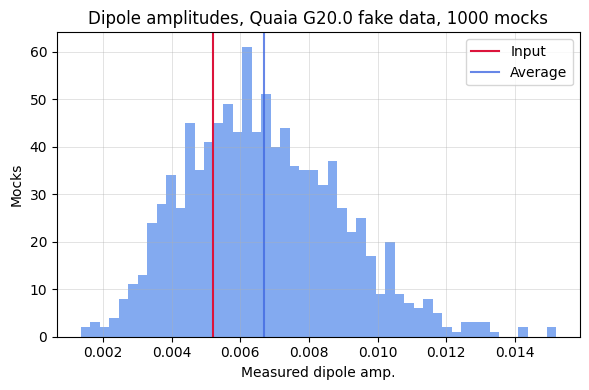

In [22]:
dipamps = np.array([
    x['dipamp'] for x in ress
])
avg_dipamp = np.mean(dipamps)
print(f"average dipole amp = {avg_dipamp:.5f}")
fig, ax = plt.subplots(figsize=(6,4), tight_layout=True)
_, _, _ = ax.hist(dipamps, color='cornflowerblue', alpha=0.8, bins=50)
ax.axvline(cat_info['expected_dipole_amp'], c='crimson', label='Input')
ax.axvline(avg_dipamp, c='royalblue', alpha=0.8, label='Average')
ax.grid(alpha=0.5, lw=0.5)
ax.set_xlabel(r'Measured dipole amp.')
ax.set_ylabel(r'Mocks')
ax.set_title(f'Dipole amplitudes, Quaia G20.0 fake data, {nmocks} mocks')
ax.legend()

I suspect the positive bias is mainly from the Cartesian parameterization---since the dipole amplitude is a sum of squares. If we used ABC to infer the dipole amplitudes with $(\mathcal D,\cos\theta,\phi)$ parameterization, I suspect this bias would disappear

In [23]:
# what's the average uncertainty?
dipamp_stds = np.array([
    x['dipamp_std'] for x in ress
])
print(f"min dipole amp std = {np.min(dipamp_stds):.6f}")
print(f"max dipole amp std = {np.max(dipamp_stds):.6f}")
print(f"avg dipole amp std = {np.mean(dipamp_stds):.6f}")

min dipole amp std = 0.002226
max dipole amp std = 0.003069
avg dipole amp std = 0.002547


### with ABC

In [30]:
ntrials = 24
qs = []
dipamps_abc = []
dipdirs_abc = []
lstsq_ress = []
for itrial in range(ntrials):
    q, res, dipamp_abc, dipdir_abc, expected_vals = get_abc_results_free_dipole(os.path.join('../results',
                            f'ABC/fake_data/{selfunc_str}_base-rate-{base_rate:.4f}_dipamp-1.0x_excess-zero',
                                                            f'trials/trial{itrial}',
                                            f'free_dipole_nside{nside}_500mocks_15iters_flat-prior-spherical',
                                                                 f'results.npy'), plot=False)
    qs.append(q)
    dipamps_abc.append(dipamp_abc)
    dipdirs_abc.append(dipdir_abc)
    # also use the least-squares fit to measure
    datamap = res['fake_data_dict']['data']['data']
    lstsq_res = standard_dipole(datamap, fake_data_dict['selfunc'], fake_data_dict['input_dipole_amp'])
    lstsq_ress.append(lstsq_res)

expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00288065  0.00120139  0.00031678]
inferred dipole has amplitude 0.00314 towards (l, b) = (238.75, 50.08) deg
z score = 0.8467
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00412372  0.00323019  0.00156386]
inferred dipole has amplitude 0.00547 towards (l, b) = (214.53, 41.91) deg
z score = -0.0832
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00498648  0.00017554  0.00258065]
inferred dipole has amplitude 0.00562 towards (l, b) = (208.56, 76.78) deg
z score = -0.1187
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00567039  0.00016793  0.00334691]
inferred dipole has amplitude 0.00659 towards (l, b) = (194.51, 76.81) deg
z score = -0.5262
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00253182  0.00063507  0.00146528]
inferred dipole has amplitude 0.00299 towards (l, b) = (201.32, 66.21) deg
z score = 0.7932
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00854583  0.00019758  0.0

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


z score = 0.3588
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0043597   0.00195288 -0.00185951]
inferred dipole has amplitude 0.00513 towards (l, b) = (262.68, 29.81) deg
z score = 0.0196
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00286468 -0.00434928  0.00230832]
inferred dipole has amplitude 0.00570 towards (l, b) = (38.32, 50.56) deg
z score = -0.1570
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00326332  0.00393269 -0.00117879]
inferred dipole has amplitude 0.00524 towards (l, b) = (237.66, 16.79) deg
z score = -0.0284
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00365075 -0.00069592  0.00274778]
inferred dipole has amplitude 0.00462 towards (l, b) = (133.04, 80.49) deg
z score = 0.1915
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00543842  0.00517084  0.0031931 ]
inferred dipole has amplitude 0.00816 towards (l, b) = (204.30, 39.16) deg
z score = -0.8980
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00551664 

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0051245  -0.00063999 -0.00141253]
inferred dipole has amplitude 0.00535 towards (l, b) = (294.77, 47.21) deg
z score = -0.0428
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00332194 -0.00217105  0.00085667]
inferred dipole has amplitude 0.00406 towards (l, b) = (358.77, 65.80) deg
z score = 0.4654
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00335417 -0.00037125  0.0025273 ]
inferred dipole has amplitude 0.00422 towards (l, b) = (151.02, 78.83) deg
z score = 0.3187
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00448981 -0.00084167 -0.00144365]
inferred dipole has amplitude 0.00479 towards (l, b) = (299.89, 45.28) deg
z score = 0.1168
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00396139 -0.00074954  0.00026055]
inferred dipole has amplitude 0.00404 towards (l, b) = (297.56, 66.48) deg
z score = 0.4000
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00829002  0.00035115  0.001

/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


expected dipole_amp = 0.0052
inferred dipole comps:  [-0.01026602  0.00373684  0.00072212]
inferred dipole has amplitude 0.01095 towards (l, b) = (243.79, 50.90) deg
z score = -1.8579
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00620664  0.00156656 -0.00052576]
inferred dipole has amplitude 0.00642 towards (l, b) = (259.46, 48.84) deg
z score = -0.3612
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00671496 -0.00196769 -0.00200234]
inferred dipole has amplitude 0.00728 towards (l, b) = (307.81, 46.77) deg
z score = -0.5809
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.00271723 -0.00042405  0.00148079]
inferred dipole has amplitude 0.00312 towards (l, b) = (193.66, 86.28) deg
z score = 0.8005
expected dipole_amp = 0.0052
inferred dipole comps:  [-0.0036459  -0.00024147  0.00070168]
inferred dipole has amplitude 0.00372 towards (l, b) = (273.50, 71.64) deg
z score = 0.3898


/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc
/tmp/ipykernel_150442/2144173106.py:6: RuntimeWarning: invalid value encountered in divide
  qmap_corr = qmap_masked / selfunc


In [34]:
dipamps_lstsq = np.array([
    x['dipamp'] for x in lstsq_ress
])

average dipole amp, ABC = 0.00557
average dipole amp, lstsq = 0.00647


Text(0.5, 0.98, 'Dipole amplitudes, Quaia G20.0 fake data, 24 mocks')

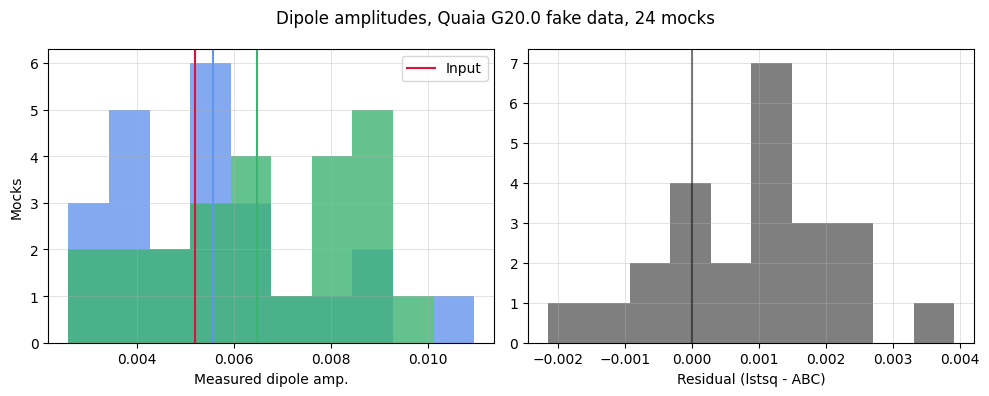

In [43]:
cs = ['cornflowerblue', 'mediumseagreen']
labels = ['ABC', 'lstsq']
fig, axs = plt.subplots(1, 2, figsize=(10,4), tight_layout=True)
bins = np.linspace(np.amin([dipamps_abc, dipamps_lstsq]), np.amax([dipamps_abc, dipamps_lstsq]), 11)
for (dipamps_, c, label) in zip([dipamps_abc, dipamps_lstsq], cs, labels):
    _, _, _ = axs[0].hist(dipamps_, color=c, bins=bins, alpha=0.8)
    avg_dipamp = np.mean(dipamps_)
    print(f"average dipole amp, {label} = {avg_dipamp:.5f}")
    axs[0].axvline(avg_dipamp, c=c, alpha=1.)
_, _, _ = axs[1].hist(dipamps_lstsq - dipamps_abc, color='k', alpha=0.5, bins=10)
axs[0].axvline(cat_info['expected_dipole_amp'], c='crimson', label='Input')
axs[1].axvline(c='k', alpha=0.5)
for ax in axs:
    ax.grid(alpha=0.5, lw=0.5)
axs[0].set_ylabel(r'Mocks')
axs[0].set_xlabel(r'Measured dipole amp.')
axs[1].set_xlabel(r'Residual (lstsq - ABC)')
axs[0].legend()
fig.suptitle(f'Dipole amplitudes, Quaia G20.0 fake data, {ntrials} mocks')

In [45]:
dipdirs_lstsq = np.array([
    x['dipdir'] for x in lstsq_ress
])

/work2/08811/aew492/frontera/venv/dipole/lib/python3.9/site-packages/skyproj/_skyproj.py:628: FutureWarning: skyproj.scatter() has been deprecated and will be removed in v2.5. Please access via skyproj.ax.scatter()
  warnings.warn(


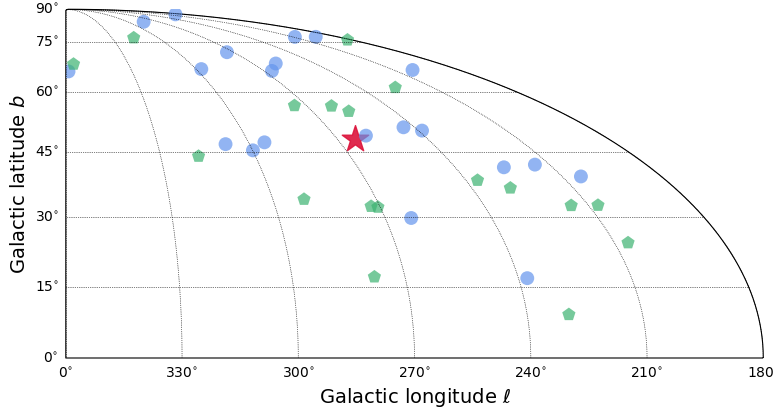

In [47]:
# direction
fig, ax = plt.subplots(figsize=(9,6))
sp = skyproj.MollweideSkyproj(ax=ax, extent=[180, 360, 0, 90])
sp.ax.tick_params(fontsize=16)

# labels and gridlines
sp.ax.set_xlabel(r'Galactic longitude $\ell$', fontsize=14)
sp.ax.set_ylabel(r'Galactic latitude $b$', fontsize=14)
sp.ax.tick_params(fontsize=12)
sp.ax.gridlines.set_alpha(0.4)

for dipdir in dipdirs_abc:
    l, b = dipdir.galactic.l.deg, dipdir.galactic.b.deg
    sp.scatter(l, b, color='cornflowerblue', edgecolor='None', ls='-',
               s=100, alpha=0.7, zorder=10, linewidths=2, marker='o')
    # sp.ax.ellipse(l, b, berr, berr, 0, color='cornflowerblue', alpha=0.7, ls='-')
    
for dipdir in dipdirs_lstsq:
    l, b = dipdir.galactic.l.deg, dipdir.galactic.b.deg
    sp.scatter(l, b, color='mediumseagreen', edgecolor='None', ls='-',
               s=100, alpha=0.7, zorder=10, linewidths=2, marker='p')

sp.scatter(cmb_dipdir.galactic.l.deg, cmb_dipdir.galactic.b.deg, color='crimson', 
        label=f'Expected (CMB)', s=400, marker='*', alpha=0.9)